In [1]:
import sys

print(sys.version)

3.14.10 (main, Nov 11 2026, 00:18:44) [Clang 23.1.3 ]


# Common Boggle Words

Which words turn up most often on a Boggle board, and which of them are worth knowing?

This notebook answers the first question by sampling boards, and then asks a few more: which words no board can show, what the best board scores and how likely it is to come up, and how this code compares with Peter Norvig's [Boggle notebook](https://github.com/norvig/pytudes/blob/main/ipynb/Boggle.ipynb), which finds high-scoring boards by hill climbing.

The first question, answered by sampling. The second needs people, not simulation. [Common on the board, rare in English](https://attobop.net/posts/boggle-words/) separates what can be simulated (how often a word appears, how many points it offers) from what cannot (whether a player knows the word, notices it in time, and is the only one to write it down). The counts below reproduce that post's exactly: the same cubes, the same dictionary and the same random seed.

## The rules

Classic Boggle has 16 cubes with a letter on each face, shaken into a 4 by 4 grid. A word is a path through neighboring cubes (horizontally, vertically or diagonally) that uses no cube twice, though a letter may repeat on different cubes. A word needs at least three letters, and the `Qu` face counts as two letters on one cube. Words score by length (Hasbro's [instructions](https://www.hasbro.com/common/instruct/boggle.pdf)):

| letters | 3 or 4 | 5 | 6 | 7 | 8 or more |
|---|---|---|---|---|---|
| points | 1 | 2 | 3 | 5 | 11 |

With several players, a word that two or more players find is crossed off every list.

## Too many boards to count

If the cubes are told apart, there are $16!$ ways to place them and $6^{16}$ ways to choose their faces:

In [2]:
from math import factorial

f"{factorial(16) * 6**16:.2e}"

'5.90e+25'

Duplicate letters and the symmetries of the square make the number of different-looking boards smaller, but not small enough. Even at a hundred million boards a second, checking them all would take a while:

In [3]:
BOARDS = 5.9e25  # 16! * 6**16 position-and-face outcomes
RATE = 1e8  # boards per second
print(f"about {BOARDS / RATE / (365.25 * 24 * 3600):.1g} years")

about 2e+10 years


Great Scott! So we sample boards instead.

## Simulating Boggle

The code for boards and word search is in `board.py`, next to this notebook, so the tests can import it too. These are the 16 cubes it uses, the "New Boggle" set sold from 1987 (or 1992; listings differ) until about 2008. The rules do not list cube faces, and editions differ, so every probability below describes this set of cubes. The README lists the sources, and the older classic set, `CLASSIC_CUBES`, appears below.

In [4]:
from boggle.board import CUBES

CUBES

[('a', 'a', 'e', 'e', 'g', 'n'),
 ('a', 'b', 'b', 'j', 'o', 'o'),
 ('a', 'c', 'h', 'o', 'p', 's'),
 ('a', 'f', 'f', 'k', 'p', 's'),
 ('a', 'o', 'o', 't', 't', 'w'),
 ('c', 'i', 'm', 'o', 't', 'u'),
 ('d', 'e', 'i', 'l', 'r', 'x'),
 ('d', 'e', 'l', 'r', 'v', 'y'),
 ('d', 'i', 's', 't', 't', 'y'),
 ('e', 'e', 'g', 'h', 'n', 'w'),
 ('e', 'e', 'i', 'n', 's', 'u'),
 ('e', 'h', 'r', 't', 'v', 'w'),
 ('e', 'i', 'o', 's', 's', 't'),
 ('e', 'l', 'r', 't', 't', 'y'),
 ('h', 'i', 'm', 'n', 'qu', 'u'),
 ('h', 'l', 'n', 'n', 'r', 'z')]

To shake the board, `rand_board` puts the cubes in a random order and shows a random face of each. Every random choice comes from a seeded `random.Random`, so each number here can be reproduced.

In [5]:
import random

from boggle.board import rand_board

board = rand_board(random.Random(0))
board

[['i', 'h', 'r', 'e'],
 ['t', 'y', 'v', 'l'],
 ['r', 'a', 's', 'e'],
 ['o', 'm', 'n', 's']]

Every cube lands in one slot, so the 16 faces come from 16 different cubes. A board is easier to read drawn; here it is, with one word traced through its cubes:

I  H  R  E
T  Y  V  L
R  A  S  E
O  M  N  S


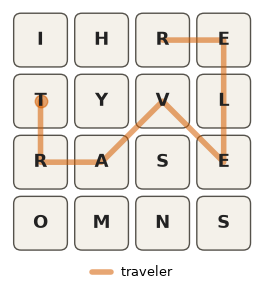

In [6]:
import matplotlib.pyplot as plt

from boggle.board import show
from boggle.figures import draw_board

faces = [face for row in board for face in row]
assert all(sum(face in cube for cube in CUBES) >= 1 for face in faces)
assert rand_board(random.Random(0)) == board  # the same seed gives the same board
print(show(board))
draw_board(board, ["traveler"])
plt.show()

To find the words on a board, we follow paths from every cube to its unused neighbors. Looking each partial path up in a set of words would waste time on paths that cannot become words, so the dictionary goes into a trie, a tree of letters ([an elegant version](http://stackoverflow.com/a/11016430)), and a path stops as soon as its letters are not a prefix of any word.

In [7]:
import json

from boggle.board import make_trie

print(json.dumps(make_trie(["apply", "apple", "apt"]), indent=2))

{
  "a": {
    "p": {
      "p": {
        "l": {
          "y": {
            "null": null
          },
          "e": {
            "null": null
          }
        }
      },
      "t": {
        "null": null
      }
    }
  }
}


In [8]:
assert make_trie(["at"]) == {"a": {"t": {None: None}}}
assert None in make_trie(["at", "ate"])["a"]["t"]  # "at" is a word and a prefix of "ate"

The `Qu` face needs care. The trie has a `q` branch followed by a `u` branch, but no `qu` branch, so looking up the whole face as one key would silently miss every Q word. `get_words` follows each letter printed on a face before moving to the next cube; the path still uses one cube.

The dictionary is ENABLE, a permissive word-game list rather than an official tournament dictionary. `load_words` checks the file's SHA-256 digest, so a changed word list cannot quietly change the results. Here are the words on the board above:

In [9]:
from boggle.board import get_words, load_words, points

words = load_words(
    "enable1.txt", sha256="a392640f14602fcbb36779eb6671d170260c06d43f41c16383e7f0e35b221b4a"
)
trie = make_trie(w for w in words if len(w) >= 3)
found = sorted(get_words(board, trie), key=lambda w: (-len(w), w))
print(
    len(words),
    "dictionary words;",
    len(found),
    "on this board, worth",
    sum(map(points, found)),
    "points:",
)
print(" ".join(found))

172820 dictionary words; 183 on this board, worth 284 points:
traveler raveler travels enamor manses martyr mavens morass morays navels ravels ravens revels romans selvas senary smarty tassel travel traves amort anele avens elver elves essay evens every lever manes manse masse maven moans moras moray navel naves never oases oaves rases ravel raven raver raves revel rhyta roams roans roman sanes satyr saver saves selva sensa sever smart snath tansy tasse trams trans trass trave trays vanes vases anes arms arty aver aves else even ever eves lens less leva levy mane mans mart mass math mays moan moas moat mora mort nary nave navy nays ness neve oath rams rase rath rave rays revs roam roan roms ryas sane sans sati save sels tams tans taro tass tavs tram tray tyre tyro vane vans vary vase vena very yams ane arm art ass ave ays els ens ess eve hit lev man mar mas mat may moa mor nam nay oar oat oms ora ort ram ran ras rat ray rev rom rya sat say sel sen tam tan tao tar tas tav thy try van va

Checks on boards small enough to read by hand. A cube is used once, though its letter may repeat elsewhere; `Qu` matches as one face; scores follow the table above.

In [10]:
from boggle.board import parse_board

tiny = make_trie(["eye", "eyey", "quit", "qit", "cat", "tac", "act"])
assert set(get_words(parse_board("eyex xxxx xxxx xxxx"), tiny)) == {"eye"}
assert set(get_words(parse_board("qitx xxxx xxxx xxxx"), tiny)) == {"quit"}
assert set(get_words(parse_board("catx xxxx xxxx xxxx"), tiny)) == {"cat", "tac"}
assert [points(w) for w in ("tea", "tees", "teens", "tenets", "setters", "teenager")] == [
    1,
    1,
    2,
    3,
    5,
    11,
]

And a check of the trie search against brute force: spell every path of up to seven letters, with no trie, and look each one up in a set of words. Both must find the same words of up to seven letters. The brute force follows every path, so it is far slower:

In [11]:
import time

from boggle.board import words_by_paths

wordset = {w for w in words if len(w) >= 3}
start = time.perf_counter()
brute = words_by_paths(board, wordset, max_len=7)
brute_time = time.perf_counter() - start
start = time.perf_counter()
fast = {w for w in get_words(board, trie) if len(w) <= 7}
trie_time = time.perf_counter() - start
assert brute == fast
print(len(fast), "words of 3 to 7 letters, found both ways")

182 words of 3 to 7 letters, found both ways


In [12]:
print(f"brute force {brute_time:.2f} s, trie {trie_time * 1000:.1f} ms")

brute force 0.74 s, trie 23.0 ms


## How many boards?

Fix one word $w$. A random board either contains it or not, so each board is a yes-or-no trial with unknown probability $p_w$, the word's **board probability**. With $n$ independent boards, the share of boards containing $w$, $\hat p_w$, estimates $p_w$, and Hoeffding's inequality bounds its error:

$$P\left(|\hat p_w - p_w| > \epsilon\right) \le 2 e^{-2n\epsilon^2}.$$

To make the right side at most $\delta$, it is enough that

$$n \ge \frac{\log(2/\delta)}{2\epsilon^2}.$$

With $\epsilon = 0.01$ and $\delta = 0.1$ that is 14,979 boards. But that is a guarantee for *one* word chosen before sampling. For $K$ words fixed in advance, a union bound replaces $\delta$ by $\delta / K$. A top-20 list is chosen *after* looking at the counts, so neither bound covers it; that needs a held-out sample. The tables below give each word an ordinary 95% Wilson interval instead, and do not claim that near-tied words are in the right order.

In [13]:
from boggle.board import hoeffding_boards

assert hoeffding_boards(0.01, 0.1) == 14_979
{k: hoeffding_boards(0.01, 0.1, words=k) for k in (1, 20, 1000)}

{1: 14979, 20: 29958, 1000: 49518}

## What appears

We draw 15,000 boards one after another from a single generator seeded with 20161126, as the post does, and count how many boards contain each word of at least three letters.

In [14]:
from tabulate import tabulate

from boggle.board import count_words, sample_boards, wilson

NBOARDS, SEED = 15_000, 20161126
start = time.perf_counter()
boards = sample_boards(NBOARDS, SEED)
counts = count_words(boards, trie, min_len=3)
sample_time = time.perf_counter() - start
lo, hi = wilson(50, 100)
assert lo < 0.5 < hi and abs((lo + hi) / 2 - 0.5) < 1e-12  # symmetric about one half


def common(min_len=3, top=15):
    """The most common words with at least min_len letters, with 95% Wilson intervals."""
    rows = sorted(((-c, w) for w, c in counts.items() if len(w) >= min_len))[:top]
    for rank, (neg, w) in enumerate(rows, start=1):
        low, high = wilson(-neg, NBOARDS)
        yield rank, w, -neg, f"{-neg / NBOARDS:.2%}", f"{low:.2%} to {high:.2%}"


print(tabulate(common(), headers=["rank", "word", "boards", "probability", "95% interval"]))

  rank  word      boards  probability    95% interval
------  ------  --------  -------------  ----------------
     1  toe         2866  19.11%         18.49% to 19.74%
     2  tee         2721  18.14%         17.53% to 18.76%
     3  tea         2691  17.94%         17.33% to 18.56%
     4  net         2682  17.88%         17.28% to 18.50%
     5  ten         2682  17.88%         17.28% to 18.50%
     6  ate         2659  17.73%         17.12% to 18.35%
     7  eta         2659  17.73%         17.12% to 18.35%
     8  set         2560  17.07%         16.47% to 17.68%
     9  tie         2525  16.83%         16.24% to 17.44%
    10  eat         2517  16.78%         16.19% to 17.39%
    11  tae         2517  16.78%         16.19% to 17.39%
    12  het         2355  15.70%         15.13% to 16.29%
    13  eth         2299  15.33%         14.76% to 15.91%
    14  ret         2239  14.93%         14.37% to 15.51%
    15  the         2193  14.62%         14.06% to 15.19%


In [15]:
print(f"{NBOARDS:,} boards shaken and searched in {sample_time:.0f} s")

15,000 boards shaken and searched in 124 s


These are the counts in the post's table, to the board:

In [16]:
assert [counts[w] for w in ("toe", "tee", "tea", "net", "ten")] == [2866, 2721, 2691, 2682, 2682]

Three-letter words dominate. With at least four letters the list changes, but stays tightly bunched:

In [17]:
print(
    tabulate(common(min_len=4), headers=["rank", "word", "boards", "probability", "95% interval"])
)

  rank  word      boards  probability    95% interval
------  ------  --------  -------------  --------------
     1  teen         922  6.15%          5.77% to 6.54%
     2  tent         917  6.11%          5.74% to 6.51%
     3  tees         911  6.07%          5.70% to 6.47%
     4  note         868  5.79%          5.42% to 6.17%
     5  teat         867  5.78%          5.42% to 6.16%
     6  toea         851  5.67%          5.31% to 6.06%
     7  toes         843  5.62%          5.26% to 6.00%
     8  tone         825  5.50%          5.15% to 5.88%
     9  nets         821  5.47%          5.12% to 5.85%
    10  test         817  5.45%          5.09% to 5.82%
    11  rote         797  5.31%          4.97% to 5.68%
    12  tote         797  5.31%          4.97% to 5.68%
    13  stet         794  5.29%          4.95% to 5.66%
    14  tets         794  5.29%          4.95% to 5.66%
    15  tens         790  5.27%          4.92% to 5.64%


For comparison, Dan Vanderkam's [sample of 50,000 boards](https://www.danvk.org/wp/2007-02-11/some-boggle-statistics/index.html) (2007) puts toe at 19.3% and tee at 19.1%, and the most common four-letter words at teen 6.7%, tees 6.6% and tent 6.0%. Those are the same words, with frequencies within about one percentage point of these. His cube set and dictionary may differ from the ones here.

## Points on offer

A common word is not necessarily a valuable one. For one player, a first measure is the **solo opportunity** of a word,

$$O(w) = s(w)\,p_w,$$

the official points $s(w)$ times the board probability: the points per board the word makes available to a player who finds everything. Summed over all words, it is the expected total score on offer per board. We compute that total two ways, summing over words and averaging over boards, and check that they agree. (Keeping each board's word list also serves the sections below.)

In [18]:
import numpy as np

opportunity = {w: points(w) * c / NBOARDS for w, c in counts.items()}
board_words = [list(get_words(b, trie)) for b in boards]
per_word = sum(opportunity.values())
per_board = np.mean([sum(map(points, ws)) for ws in board_words])
assert abs(per_word - per_board) < 1e-9
print(
    f"{per_word:.2f} points on offer per board, {np.mean([len(ws) for ws in board_words]):.2f} words"
)

rows = sorted(opportunity.items(), key=lambda item: -item[1])[:12]
print(
    tabulate(
        [(w, points(w), f"{counts[w] / NBOARDS:.2%}", f"{o:.4f}") for w, o in rows],
        headers=["word", "points", "probability", "solo opportunity"],
    )
)

140.02 points on offer per board, 97.83 words
word      points  probability      solo opportunity
------  --------  -------------  ------------------
toe            1  19.11%                     0.1911
tee            1  18.14%                     0.1814
tea            1  17.94%                     0.1794
ten            1  17.88%                     0.1788
net            1  17.88%                     0.1788
ate            1  17.73%                     0.1773
eta            1  17.73%                     0.1773
set            1  17.07%                     0.1707
tie            1  16.83%                     0.1683
eat            1  16.78%                     0.1678
tae            1  16.78%                     0.1678
het            1  15.70%                     0.157


Dan Vanderkam's sample of five million boards gives 140.97 points and 98.53 words per board, close to the figures here. At one point each, three- and four-letter words supply most of the opportunity, so the list above is the most-common list again.

## Common on the board, rare in English

An earlier version of this notebook ranked words with a TF-IDF-like score: board frequency times a decreasing function of a word's count in a text corpus, giving words missing from the corpus the smallest count found. The post explains why that was the wrong tool. There are no documents, so "TF-IDF" is a misnomer. A word can be missing from a corpus because of spelling, tokenization or coverage, not only because it is obscure. And a word's corpus frequency is not whether players know it, which is not whether they notice it on the board.

So the two measurements stay separate. Below, English frequency comes from `wordfreq` 3.1.1 as a Zipf value (about 1 for rare words, 7 for the most common). Words below its cutoff are marked unlisted, rather than given a number.

In [19]:
from wordfreq import zipf_frequency

eight = ("toea", "teat", "stet", "nett", "seta", "rete", "tret", "sett")
print(
    tabulate(
        [
            (
                w,
                f"{counts[w] / NBOARDS:.2%}",
                f"{opportunity[w]:.4f}",
                f"{zipf_frequency(w, 'en'):.2f}" if zipf_frequency(w, "en") else "unlisted",
            )
            for w in eight
        ],
        headers=["word", "board probability", "solo opportunity", "Zipf"],
    )
)

word    board probability      solo opportunity  Zipf
------  -------------------  ------------------  --------
toea    5.67%                            0.0567  unlisted
teat    5.78%                            0.0578  2.50
stet    5.29%                            0.0529  1.83
nett    5.23%                            0.0523  2.41
seta    5.10%                            0.051   2.28
rete    4.89%                            0.0489  2.04
tret    4.81%                            0.0481  1.63
sett    4.67%                            0.0467  2.27


The plot puts every word that appears on at least 15 boards on both axes. The highlighted words are not beaten on both measures at once by any other word: more opportunity *and* rarer in English. To avoid reading noise as signal, that frontier is computed separately in each half of the sample, and only words on both halves' frontiers are highlighted.

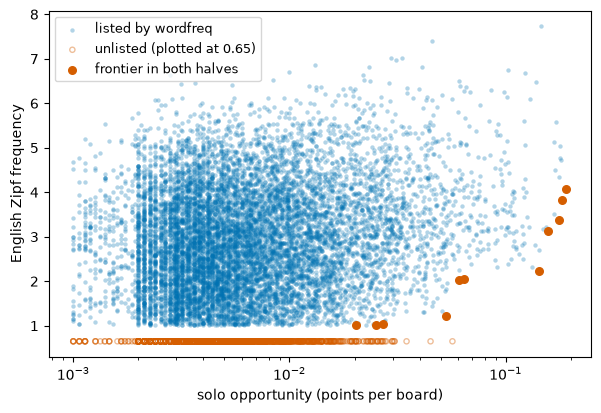

11 stable frontier words: toe tee eta het oes teg wae tets neats leets teethe


In [20]:
import matplotlib.pyplot as plt

half = NBOARDS // 2
first, second = count_words(boards[:half], trie), count_words(boards[half:], trie)


def frontier(sample):
    """Words that no other word beats on both solo opportunity and rarity."""
    rows = [(points(w) * c / half, zipf_frequency(w, "en"), w) for w, c in sample.items() if c >= 8]
    rows = [r for r in rows if r[1] > 0 and r[0] >= 0.003]
    best, out = float("inf"), set()
    for _, z, w in sorted(rows, key=lambda r: (-r[0], r[1])):
        if z < best:
            out.add(w)
            best = z
    return out


stable = frontier(first) & frontier(second)
shown = [w for w, c in counts.items() if c >= 15]
zipf = {w: zipf_frequency(w, "en") for w in shown}
fig, ax = plt.subplots(figsize=(7, 4.5))
listed = [w for w in shown if zipf[w] > 0]
unlisted = [w for w in shown if zipf[w] == 0]
ax.scatter(
    [opportunity[w] for w in listed],
    [zipf[w] for w in listed],
    s=10,
    alpha=0.3,
    color="#0072B2",
    linewidths=0,
    label="listed by wordfreq",
)
ax.scatter(
    [opportunity[w] for w in unlisted],
    [0.65] * len(unlisted),
    s=14,
    alpha=0.4,
    facecolors="none",
    edgecolors="#D55E00",
    label="unlisted (plotted at 0.65)",
)
ax.scatter(
    [opportunity[w] for w in stable],
    [zipf[w] for w in stable],
    s=30,
    color="#D55E00",
    label="frontier in both halves",
)
ax.set_xscale("log")
ax.set_xlabel("solo opportunity (points per board)")
ax.set_ylabel("English Zipf frequency")
ax.legend(loc="upper left", fontsize=9)
plt.show()
print(
    len(stable), "stable frontier words:", " ".join(sorted(stable, key=lambda w: -opportunity[w]))
)

These are words to *test*, not to memorize. Whether learning _toea_ earns points depends on whether a player then finds it in time, and on whether opponents find it too; the post sets out the experiment that would measure that.

## How many words on a board?

The number of words varies a lot from board to board. Here is its distribution over all the sampled boards:

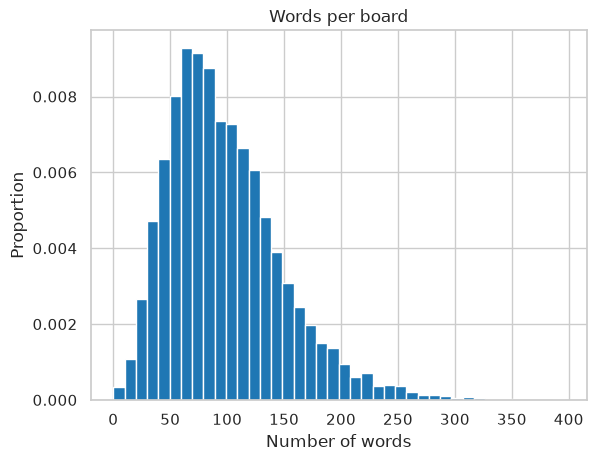

mean 97.8, median 90, fewest 0, most 396


In [21]:
import seaborn

seaborn.set_context("notebook")
seaborn.set_style("whitegrid")

num_words = [len(ws) for ws in board_words]
plt.hist(num_words, bins=40, density=True)
plt.title("Words per board")
plt.xlabel("Number of words")
plt.ylabel("Proportion")
plt.show()
print(
    f"mean {np.mean(num_words):.1f}, median {np.median(num_words):.0f}, fewest {min(num_words)}, most {max(num_words)}"
)

## Best proportion of vowels

A friend once said that the best Boggle boards are about 40% vowels, where best means the most words. We can check: group the boards by their number of vowels, and average the number of words of four or more letters in each group, with a 95% interval.

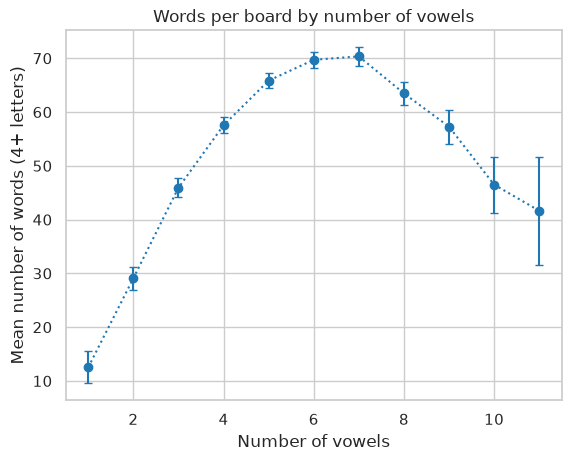

{0: 6, 1: 89, 2: 455, 3: 1285, 4: 2458, 5: 3281, 6: 3267, 7: 2289, 8: 1207, 9: 466, 10: 149, 11: 37, 12: 8, 13: 3} (boards with that many vowels)
{1: 12.6, 2: 29.1, 3: 45.9, 4: 57.6, 5: 65.8, 6: 69.7, 7: 70.4, 8: 63.5, 9: 57.3, 10: 46.5, 11: 41.6} (mean words; groups of fewer than 30 boards left out)


In [22]:
from collections import defaultdict

vowels = set("aeiou")  # for simplicity, these are the only vowels
words_by_vowels = defaultdict(list)
for b, ws in zip(boards, board_words, strict=True):
    n_vowels = sum(face[0] in vowels for row in b for face in row)
    words_by_vowels[n_vowels].append(sum(len(w) >= 4 for w in ws))

x = [v for v in sorted(words_by_vowels) if len(words_by_vowels[v]) >= 30]
means = [np.mean(words_by_vowels[v]) for v in x]
halves = [1.96 * np.std(words_by_vowels[v], ddof=1) / np.sqrt(len(words_by_vowels[v])) for v in x]
plt.errorbar(x, means, yerr=halves, fmt="o:", capsize=3)
plt.title("Words per board by number of vowels")
plt.xlabel("Number of vowels")
plt.ylabel("Mean number of words (4+ letters)")
plt.show()
print(
    {v: len(words_by_vowels[v]) for v in sorted(words_by_vowels)}, "(boards with that many vowels)"
)
print(
    {v: round(float(m), 1) for v, m in zip(x, means, strict=True)},
    "(mean words; groups of fewer than 30 boards left out)",
)

The peak is at six and seven vowels, 37.5% and 44% of the board, and their intervals overlap; 40% sits between them, so the remark holds up. Boards with very few or very many vowels are rare, which is why the intervals widen at the ends.

## Words never seen

The sample found many words, but not every word that can appear. How much is missing? Count each appearance of a word on a board as one observation. Turing and Good estimated the chance that the next observation is a new word by a simple share: the share of observations that are words seen exactly once. The post [You've seen 100 species. How many exist?](https://attobop.net/posts/unseen-species/) explains why that share is a sound estimate, and why it says nothing by itself about *how many* unseen words there are.

In [23]:
seen_once = sum(c == 1 for c in counts.values())
appearances = sum(counts.values())
playable = sum(len(w) >= 3 for w in words)
print(f"{len(counts):,} different words seen, of {playable:,} dictionary words with 3+ letters")
print(
    f"{seen_once:,} seen on exactly one board, out of {appearances:,} appearances: "
    f"missing mass about {seen_once / appearances:.4%}"
)

41,171 different words seen, of 172,724 dictionary words with 3+ letters
11,018 seen on exactly one board, out of 1,467,424 appearances: missing mass about 0.7508%


So about one word appearance in 130 on a fresh board would be a word this sample never saw. Yet more than a quarter of the words that were seen turned up on only one board: the tail is long.

Are the words never seen rare on boards, or impossible with these cubes? This one the sample cannot settle, but a short argument can. Call a word **possible** if some shake of the cubes shows it along some path. Split the word into faces, with "qu" as one face (a q followed by anything else cannot be spelled, since no face shows a q alone). If each face can be given its own cube that carries it, the word is possible: lay those cubes along a path that visits all 16 slots, row by row and turning at each end, with the right faces up. Each slot on that path is a neighbor of the one before, so the word reads along it. If no such choice of cubes exists, no board shows the word. So where the letters fall on the board does not matter, only whether each face gets a different cube. That is a **matching** problem, which `possible` solves with augmenting paths.

When there is no matching, Hall's theorem names a reason: a set of faces that the word uses more often than there are cubes carrying any of them. `obstruction` returns that set. With these cubes, "fake" is impossible because f and k are both only on the cube A F F K P S, and "jazz" because one cube carries the only z. The tests compare `possible` with a search over every choice of cubes on small sets, and build a board for every possible word (`witness_board`) on which the solver finds it.

In [24]:
from collections import Counter

from boggle.board import obstruction, possible, witness_board

assert possible("toe") and not possible("fake") and not possible("qat")
assert (
    obstruction("fake") == ("f", "k") and obstruction("jazz") == ("z",) and obstruction("toe") == ()
)
assert "toe" in get_words(witness_board("toe"), trie)
distinct = {w for w in words if len(w) >= 3}  # the list holds "are" twice
unseen = distinct - set(counts)
impossible = {w for w in distinct if not possible(w)}
assert impossible <= unseen
print(
    f"{len(distinct):,} different words of 3+ letters: {len(distinct) - len(impossible):,} possible, {len(impossible):,} impossible"
)
print(
    f"{len(unseen):,} never seen: {len(impossible):,} impossible and {len(unseen - impossible):,} possible but missed"
)
reasons = Counter(obstruction(w) for w in impossible)
top = sorted(reasons.items(), key=lambda item: (-item[1], item[0]))[:8]
print(tabulate([(" ".join(r), n) for r, n in top], headers=["reason", "words"]))

172,723 different words of 3+ letters: 160,719 possible, 12,004 impossible
131,552 never seen: 12,004 impossible and 119,548 possible but missed


reason      words
--------  -------
length       2313
b            2050
f            1940
f k           846
k             579
c             472
z             398
b j           378


So 12,004 of the never-seen words cannot appear at all, and the other 119,548 are possible but did not turn up in 15,000 boards. Most of the impossible words are too long (more than 16 faces) or need twice a letter that only one cube carries, such as b or f. Among the possible words, about 74% were never seen: for nearly all of the dictionary, a sample of this size says only that a word is rare.

## The best board

In 2025 Dan Vanderkam [proved by exhaustive search](https://www.danvk.org/2025/04/23/boggle-solved.html) that no 4 by 4 board scores more than `perslatgsineters` with the ENABLE2K word list: 3,625 points from 1,045 words. His search covered every arrangement of letters, not only those a set of cubes can roll. Here is that board, read row by row, scored with this notebook's word list and solver:

1044 words, 3623 points; the longest:
replastering plasterings argentites elaterites plastering replasters sterilants argentite elaterins elaterite entailers graplines


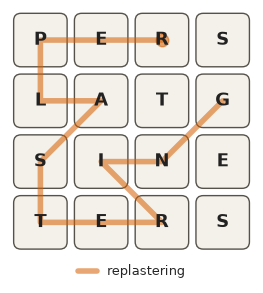

In [25]:
from boggle.board import parse_board, score

best = parse_board("perslatgsineters")
best_words = sorted(get_words(best, trie), key=lambda w: (-len(w), w))
print(len(best_words), "words,", score(best, trie), "points; the longest:")
print(" ".join(best_words[:12]))
draw_board(best, [best_words[0]])
plt.show()

That is one word and two points short of his figures, because he used another word list. ENABLE2K is the list released in 2000; which release `enable1.txt` is, nobody seems to have recorded (the README traces the copy). The folder now holds ENABLE2K too, as `enable2k.txt`, the copy in his [repository](https://github.com/danvk/hybrid-boggle/blob/main/wordlists/enable2k.txt) (commit 0c53977). The two lists differ by 895 words (802 only in ENABLE2K, 93 only in `enable1.txt`), and the only one on this board is *tenge* (five letters, two points). With ENABLE2K the same solver finds his 3,625 points and 1,045 words:

In [26]:
words2k = load_words(
    "enable2k.txt", sha256="f1e9b50e535a31d0d8451f7b373bb7966637d225e256a7c485983a0c7545fcd3"
)
trie2k = make_trie(w for w in words2k if len(w) >= 3)
best_words2k = set(get_words(best, trie2k))
print(
    len(words2k),
    "words in ENABLE2K;",
    len(best_words2k),
    "on the best board, worth",
    score(best, trie2k),
    "points",
)
print("only with ENABLE2K:", sorted(best_words2k - set(best_words)))

173528 words in ENABLE2K; 1045 on the best board, worth 3625 points
only with ENABLE2K: ['tenge']


## How likely is the best board?

A shake puts each cube in a slot and turns one face of each up. If the cubes are told apart, the $16! \cdot 6^{16}$ outcomes are equally likely. To count the outcomes that give a particular board, let $A_{ij}$ be the number of faces of cube $i$ that show the letter wanted in slot $j$. Fixing which cube goes in each slot, a permutation $\sigma$, leaves $\prod_j A_{\sigma(j)j}$ ways to choose the faces. Summing over all placements gives

$$\text{ways} = \sum_{\sigma} \prod_{j} A_{\sigma(j)\,j} = \operatorname{perm}(A),$$

the **permanent** of $A$: the determinant without its signs. Without the signs there is no fast elimination, but Ryser's formula,

$$\operatorname{perm}(A) = (-1)^n \sum_{S \subseteq \{1,\dots,n\}} (-1)^{|S|} \prod_{i=1}^{n} \sum_{j \in S} A_{ij},$$

sums over the $2^{16} = 65{,}536$ sets of columns instead of the $16!$ placements. It follows from inclusion and exclusion: the product counts the ways to give each cube some slot in $S$, and the alternating sum keeps only the ways that fill every slot. The tests check `permanent` against the definition on random matrices up to 7 by 7, and `roll_ways` against an enumeration of every shake of a three-cube set.

For the best board, $A$ is mostly zeros, and the count is exact:

In [27]:
from itertools import permutations
from math import prod

from boggle.board import face_counts, orientations, permanent, roll_chance, roll_ways

M = [[1, 2, 0], [0, 1, 3], [2, 0, 1]]
assert permanent([[1, 2], [3, 4]]) == 1 * 4 + 2 * 3  # the determinant would be 4 - 6
assert permanent(M) == sum(prod(M[i][s[i]] for i in range(3)) for s in permutations(range(3)))

A = face_counts([face for row in best for face in row])
print(" " * 8 + " ".join(face for row in best for face in row))
for cube, counts_row in zip(CUBES, A, strict=True):
    print(f"{''.join(cube):8}" + " ".join(str(c) if c else "." for c in counts_row))
ways = roll_ways(best)
print(f"{ways:,} of the {factorial(16) * 6**16:,} outcomes give this board")

        p e r s l a t g s i n e t e r s
aaeegn  . 2 . . . 2 . 1 . . 1 2 . 2 . .
abbjoo  . . . . . 1 . . . . . . . . . .
achops  1 . . 1 . 1 . . 1 . . . . . . 1
affkps  1 . . 1 . 1 . . 1 . . . . . . 1
aoottw  . . . . . 1 2 . . . . . 2 . . .
cimotu  . . . . . . 1 . . 1 . . 1 . . .
deilrx  . 1 1 . 1 . . . . 1 . 1 . 1 1 .
delrvy  . 1 1 . 1 . . . . . . 1 . 1 1 .
distty  . . . 1 . . 2 . 1 1 . . 2 . . 1
eeghnw  . 2 . . . . . 1 . . 1 2 . 2 . .
eeinsu  . 2 . 1 . . . . 1 1 1 2 . 2 . 1
ehrtvw  . 1 1 . . . 1 . . . . 1 1 1 1 .
eiosst  . 1 . 2 . . 1 . 2 1 . 1 1 1 . 2
elrtty  . 1 1 . 1 . 2 . . . . 1 2 1 1 .
himnquu . . . . . . . . . 1 1 . . . . .
hlnnrz  . . 1 . 1 . . . . . 2 . . . 1 .


1,054,080 of the 59,025,489,844,657,012,604,928,000 outcomes give this board


The count depends only on which faces are wanted, not on where, so turning or mirroring the board does not change it. The board looks different in each of its eight orientations, so the chance of rolling it in some orientation is exactly eight times the chance of one:

In [28]:
chance, one_way = roll_chance(best), roll_chance(best, turned=False)
assert len(orientations(best)) == 8 and chance == 8 * one_way
print(
    chance,
    f"= 1 in {float(1 / chance):.3e} in any orientation; 1 in {float(1 / one_way):.3e} as printed",
)
print(
    f"at one shake a second, about {float(1 / chance) / (365.25 * 24 * 3600):.2g} years per sighting"
)

61/426978369825354547200 = 1 in 7.000e+18 in any orientation; 1 in 5.600e+19 as printed
at one shake a second, about 2.2e+11 years per sighting


His post estimates the odds at around 1 in $10^{19}$, without a derivation; this is the same order of magnitude for this set of cubes. He also reports that the top boards can be rolled with both the old (before 1987) and the new cubes. With the classic cubes the count is smaller, so the chance is lower:

In [29]:
from boggle.board import CLASSIC_CUBES

classic = roll_chance(best, CLASSIC_CUBES)
print(
    f"{roll_ways(best, CLASSIC_CUBES):,} outcomes per orientation; {classic} = 1 in {float(1 / classic):.3e} in any orientation"
)
print(
    f"{sum(possible(w, CLASSIC_CUBES) for w in distinct):,} of the {len(distinct):,} words are possible with the classic cubes"
)

221,616 outcomes per orientation; 19/632560547889414144000 = 1 in 3.329e+19 in any orientation


169,378 of the 172,723 words are possible with the classic cubes


The classic cubes make the best board about 4.8 times rarer, but they can spell far more of the list. The new set puts its only F and its only K on one cube, A F F K P S, so no word with an f and a k, two fs or two ks can appear; the classic set has each letter on two cubes.

## Against random boards

The 15,000 sampled boards above give a sense of scale. Their scores:

In [30]:
scores = np.array([sum(map(points, ws)) for ws in board_words])
top = int(np.argmax(scores))
print("\n".join(" ".join(row) for row in boards[top]))
print(f"best sampled board: {scores[top]} points, {len(board_words[top])} words (board {top})")
print(
    "percentiles 50, 90, 99, 99.9:",
    np.percentile(scores, [50, 90, 99, 99.9]).round().astype(int).tolist(),
)
print(f"mean {scores.mean():.1f}, standard deviation {scores.std(ddof=1):.1f}")
low, high = wilson(int((scores >= 1000).sum()), NBOARDS)
print(f"boards of 1,000+ points: {(scores >= 1000).sum()} (95% interval up to {high:.2%})")
print(f"the best board is worth {score(best, trie) / scores.mean():.1f} average boards")

s t r d
s e a t
t n i s
e s a k
best sampled board: 969 points, 387 words (board 12856)
percentiles 50, 90, 99, 99.9: [119, 257, 452, 656]
mean 140.0, standard deviation 91.7
boards of 1,000+ points: 0 (95% interval up to 0.03%)
the best board is worth 25.9 average boards


The best of 15,000 random boards scores under 1,000 points, about a quarter of the best board's 3,623. The best board is worth about 26 average boards, and it sits so far in the tail that a sample can say nothing about the boards near it; only a search like Vanderkam's can.

## What each cube is worth

Which cubes carry the score? Replace one cube by a **blank**, a face that spells nothing, and the board loses every word whose every path passes through that cube. A word with a second path that avoids the cube survives. So one pass over the paths, recording for each word the slots common to all its paths (`word_slots`, as a bit mask), gives the loss for all 16 cubes at once. The tests check that this matches rescoring the board with each cube blanked in turn.

`sample_layouts` draws the same 15,000 boards as before, from the same seed, but also records which cube landed in each slot. The **value** of a cube is then its mean loss over the boards, with a 95% interval from the normal approximation:

In [31]:
from boggle.board import all_cube_losses, sample_layouts

layouts = sample_layouts(NBOARDS, SEED)
assert [b for _, b in layouts] == boards
losses = np.array(all_cube_losses(layouts, trie))
value, half = losses.mean(axis=0), 1.96 * losses.std(axis=0, ddof=1) / np.sqrt(NBOARDS)
rows = [
    (
        " ".join(CUBES[c]),
        f"{value[c]:.1f}",
        f"{value[c] - half[c]:.1f} to {value[c] + half[c]:.1f}",
        f"{value[c] / scores.mean():.0%}",
    )
    for c in np.argsort(-value)
]
print(
    tabulate(
        rows,
        headers=["cube", "points lost", "95% interval", "of the mean score"],
        disable_numparse=True,
    )
)
print(
    f"sum of the 16 losses {losses.sum(axis=1).mean():.0f} points, against a mean score of {scores.mean():.0f}"
)

cube          points lost    95% interval    of the mean score
------------  -------------  --------------  -------------------
e i o s s t   45.0           44.3 to 45.8    32%
a a e e g n   43.7           42.9 to 44.4    31%
e e i n s u   41.6           40.9 to 42.4    30%
e l r t t y   39.6           38.9 to 40.3    28%
d i s t t y   39.5           38.8 to 40.1    28%
a c h o p s   39.0           38.3 to 39.7    28%
a o o t t w   38.4           37.7 to 39.1    27%
d e i l r x   36.8           36.1 to 37.5    26%
e e g h n w   36.3           35.6 to 37.0    26%
d e l r v y   35.8           35.1 to 36.5    26%
h l n n r z   35.1           34.4 to 35.8    25%
a f f k p s   34.9           34.3 to 35.5    25%
c i m o t u   34.2           33.6 to 34.8    24%
e h r t v w   34.2           33.5 to 34.8    24%
a b b j o o   32.4           31.7 to 33.0    23%
h i m n qu u  28.4           27.9 to 29.0    20%
sum of the 16 losses 595 points, against a mean score of 140


Blanking any one cube costs a fifth to a third of the score. The cube with E, I, O, S, S, T costs the most, about 45 points; the Qu cube costs the least, about 28, and its one interval does not overlap any other's. Most neighbors in the table have overlapping intervals, so their order is not settled by this sample. The losses add up to about four times the mean score because a long word needs many cubes, and blanking any of them loses it: each word is counted once for every cube it cannot do without.

## Norvig's Boggle and Inverse Boggle

Peter Norvig's [Boggle notebook](https://github.com/norvig/pytudes/blob/main/ipynb/Boggle.ipynb) in pytudes (January 2020; read here at commit 3b4c5dd) solves the same problem with a different representation, and then turns it around. His board is a dict from coordinates to letters with precomputed neighbors, and his word search uses a set of all word prefixes where this one uses a trie. He reads `enable1.txt`, keeps words of three or more letters, and scores them with the same table: 1 point for three or four letters, then 2, 3, 5 and 11. His boards are 5 by 5 as well as 4 by 4, so `get_words` and `parse_board` here take any square board.

He reports three scores. All three are reproduced here, word for word in count:

In [32]:
norvig = {  # board, (points, words) as printed in his notebook
    "PUZZL WORDE BOGGL SEARC FINDH": (449, 252),
    "QEST ANSI XWEO YRSN": (245, 125),
    "RSTCS DEIAE GNLRP EATES MSSID": (10_112, 2_290),  # Boyan's board
}
for letters, (pts, nwords) in norvig.items():
    found = set(get_words(parse_board(letters), trie))
    assert (sum(map(points, found)), len(found)) == (pts, nwords)
    print(f"{letters:30} {pts:6,} points, {nwords:5,} words: agrees")

PUZZL WORDE BOGGL SEARC FINDH     449 points,   252 words: agrees
QEST ANSI XWEO YRSN               245 points,   125 words: agrees
RSTCS DEIAE GNLRP EATES MSSID  10,112 points, 2,290 words: agrees


The agreement is not automatic. His copy of `enable1.txt` has 172,724 different words of three or more letters, and this one 172,723: his has *areole* where this one repeats *are* (the README traces the two copies). No board here can spell *areole*, so the counts agree. His `Q` stands for `Qu`, as `parse_board`'s does.

The 5 by 5 board comes from Justin Boyan's PhD thesis (Carnegie Mellon, 1998), where it was found by a learned search over boards. Drawn, with its longest word:

['malapertnesses', 'desperateness', 'precisenesses', 'malapertness', 'materialness', 'paltrinesses']


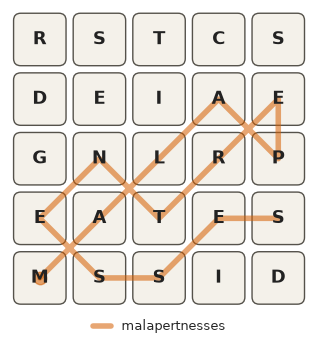

In [33]:
boyan = parse_board("RSTCS DEIAE GNLRP EATES MSSID")
boyan_words = sorted(get_words(boyan, trie), key=lambda w: (-len(w), w))
print(boyan_words[:6])
draw_board(boyan, [boyan_words[0]])
plt.show()

Big Boggle's [instructions](https://winning-moves.com/images/BigBoggle_Rules_2026.pdf) count only words of four or more letters, with the same points from there on. With that rule the same board scores less:

In [34]:
trie4 = make_trie(w for w in words if len(w) >= 4)
found4 = set(get_words(boyan, trie4))
print(f"{sum(map(points, found4)):,} points from {len(found4):,} words of four or more letters")

9,968 points from 2,146 words of four or more letters


### Inverse Boggle

Norvig's **Inverse Boggle** asks for the board with the highest score. There are $26^{25} \approx 2 \times 10^{35}$ boards of 5 by 5 letters, so he uses **hill climbing**: change one square to a random letter, drawn from the letters of the cubes, and keep the change if the score does not fall. From two boards, 500 changes gave him roughly ten times the starting score. From Boyan's board, 500 random changes found nothing better.

`hill_climb` follows his description. Starting from the board drawn at the top, with seed 1 and 1,000 changes:

A  T  E  S
S  L  T  R
E  A  I  E
R  G  N  S
284 points at the start, 3,102 after 1,000 changes; 27 of them raised the score


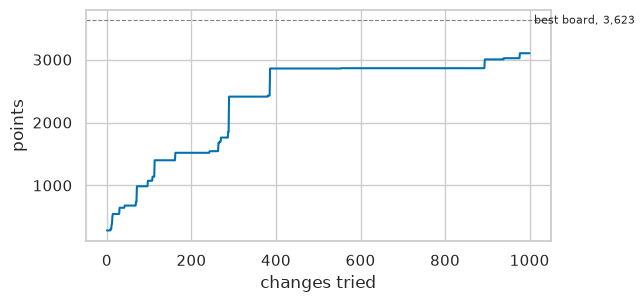

In [35]:
from boggle.board import hill_climb

climbed, history = hill_climb(board, trie, steps=1_000, rng=random.Random(1))
print(show(climbed))
print(
    f"{history[0]} points at the start, {history[-1]:,} after {len(history) - 1:,} changes; "
    f"{len(set(history)) - 1} of them raised the score"
)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(history, color="#0072B2")
ax.axhline(score(best, trie), color="gray", lw=0.8, ls="--")
ax.text(len(history), score(best, trie), " best board, 3,623", va="center", fontsize=8)
ax.set_xlabel("changes tried")
ax.set_ylabel("points")
plt.show()

The climb goes up in steps, reaches about 2,900 points after 400 changes, stalls for 500 more, and ends at 3,102, which is 86% of the best board's 3,623 and eleven times its start. That is one run, from one seed, so it shows the shape of a climb, not how often one succeeds.

Norvig's 500 random changes left Boyan's board where it was, which suggests but does not show that no single change helps. With 25 squares and 25 other letters for each, there are only 625 boards one change away, so we can score them all. `one_square_changes` does that in a pool of processes:

In [36]:
from boggle.board import one_square_changes

start = time.perf_counter()
neighbors = one_square_changes(boyan, trie)
neighbors_time = time.perf_counter() - start
top3 = sorted(neighbors.items(), key=lambda kv: -kv[1])[:3]
print(
    f"{len(neighbors)} boards one change away; the best scores {top3[0][1]:,}, against {score(boyan, trie):,}"
)
print("the three best changes (row, column, new letter):", [(k, v) for k, v in top3])

625 boards one change away; the best scores 10,046, against 10,112
the three best changes (row, column, new letter): [((0, 4, 'd'), 10046), ((4, 3, 'e'), 9979), ((0, 4, 'h'), 9931)]


In [37]:
print(f"{len(neighbors)} boards scored in {neighbors_time:.0f} s")

625 boards scored in 54 s


Every one of the 625 is worse, so Boyan's board is a strict local maximum for one-square changes: exact, by checking every case. A hill climb that reaches it can never leave it, and only a change of two or more squares at once, or a swap, could find something better nearby, as Norvig suggests. For 4 by 4 boards Vanderkam's search settled the question; for 5 by 5 boards, whether Boyan's board is the best is open.

## Questions left open

- **Findability and cancellation.** Board probability and solo opportunity can be simulated. Whether a player finds a word, and whether an opponent finds it too, needs an experiment with people; the post describes one.
- **Other editions.** Big Boggle (5 by 5) and Super Big Boggle (6 by 6) have different cubes and minimum lengths. Their cube sets would need transcribing from the physical games first. The solver already handles their boards.
- **The best 5 by 5 board.** Boyan's board is a local maximum for one-square changes; whether any 5 by 5 board scores more than 10,112 with `enable1.txt` is open.
- **Unseen words.** The exact count of possible words, 160,719, lets estimators of how many words a sample has not seen be scored against the truth. `unseen.py` does this; the estimators reach 26% to 36% of the truth from these 15,000 boards (see `results/unseen.md`).
- **Exact probabilities.** The chance of a whole board is a permanent, computed exactly above. `chance.py` computes the board probability of every word of two or three faces exactly ("toe" is 19.10%) and bounds every longer word's from above; the exact chance of longer words is still open.